# Flow curves, limits and dimensionless groups of the Herschel–Bulkley model

Before fitting data or solving flows, it pays to know the Herschel–Bulkley (HB) law well: what each of its three parameters does to the flow curve, how it reduces to the Newtonian, power-law and Bingham models, what the apparent viscosity does at low and high rates, how the one-dimensional law is generalized to three dimensions with a yield criterion, and which dimensionless numbers an engineer uses to judge whether the yield stress matters in a given flow. This notebook works through all of these with short calculations, reproduces Fig. 4 of the review, and ends with the worked pipe-flow example of the Supplementary Material, where every dimensionless group of Table IV is evaluated for one slurry pipeline.

### Where this is in the review
- **Sec. IV** (The constitutive law and its assumptions): introduction and **Eq. (3)**; **Sec. IV A** (tensorial law, **Eq. (4)**); **Sec. IV B** (yield function and flow rule: von Mises and Tresca criteria); **Sec. IV C** (parameters and dimensionless groups, **Eqs. (8)–(9)**, **Table IV**); **Sec. IV E** (extensional flows, **Eqs. (11)–(12)**); **Table V** (notation, following the Society of Rheology nomenclature of Dealy, 1995).
- **Fig. 4** (flow curves and apparent viscosity); script `scripts/fig04_flow_curves.py`.
- **Sec. VII A–B**: pipe flow rate, **Eq. (19)**, and the threshold for flow, **Eq. (22)**.
- Supplementary Notes **S1** (signed one-dimensional form and nondimensionalization), **S9 A** and **E** (pipe flow and friction factors), **S12 A** (Fig. S7, the friction-factor chart), **S15 B** (worked Examples 1 and 3, reproduced here) and **S19 C** (list of dimensionless groups).

### Learning objectives
After working through this notebook you should be able to
1. write the HB law and recover its Newtonian, power-law and Bingham limits;
2. compute the apparent viscosity and its two asymptotes, and explain why the low-rate slope of $-1$ does not identify HB behavior;
3. evaluate the tensorial HB law for a given velocity gradient, check whether a stress state has yielded with the von Mises criterion, and compare it with Tresca;
4. define and compute the Bingham, plasticity, Hedström, Metzner–Reed Reynolds and gravity yield numbers, stating the length and velocity scales used;
5. solve the laminar HB pipe-flow problem for the wall stress at a given flow rate and check the result with the friction factor.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))

import hbstyle as hs   # house style, palette C and HB helper functions (we never call hs.save)
C = hs.C
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())
from scipy.optimize import brentq
from hb_prediction import pipe_flux, pressure_gradient   # exact no-slip HB pipe flow (SI units)

data folder found: True


## 1. The HB law and its special cases

In steady simple shear the yielded material obeys

$$\sigma = \sigma_y + K\dot\gamma^{\,n},\qquad \dot\gamma>0,\ \ \sigma>\sigma_y, \tag{3}$$

with yield stress $\sigma_y$ (Pa), consistency $K$ (Pa s$^n$) and flow index $n$ (dimensionless). Below $\sigma_y$ the material does not flow. The model contains three classical laws:

| model | $\sigma_y$ | $n$ | law |
|---|---|---|---|
| Newtonian | 0 | 1 | $\sigma = \mu\dot\gamma$ ($K=\mu$) |
| power law (Ostwald–de Waele) | 0 | any | $\sigma = K\dot\gamma^{\,n}$ |
| Bingham plastic | $>0$ | 1 | $\sigma = \sigma_y + \mu_p\dot\gamma$ ($K = \mu_p$, the plastic viscosity) |

For $n<1$ the yielded branch is concave (shear thinning of the excess stress), for $n>1$ convex. We use the helper `hb_stress` of `scripts/hbstyle.py`, which is exactly Eq. (3), and check the limits numerically.

In [2]:
g = np.logspace(-3, 3, 13)                          # shear rates (1/s)
# Newtonian: sigma_y = 0, n = 1  ->  sigma = mu * gdot
assert np.allclose(hs.hb_stress(g, 0.0, 2.5, 1.0), 2.5 * g)
# power law: sigma_y = 0  ->  sigma = K gdot^n
assert np.allclose(hs.hb_stress(g, 0.0, 3.0, 0.5), 3.0 * np.sqrt(g))
# Bingham: n = 1  ->  sigma = sigma_y + mu_p gdot
assert np.allclose(hs.hb_stress(g, 8.0, 1.0, 1.0), 8.0 + g)
print("Newtonian, power-law and Bingham limits of Eq. (3) verified")

Newtonian, power-law and Bingham limits of Eq. (3) verified


**Two useful reparameterizations** (Sec. IV C). The units of $K$ change with $n$, and $K$ and $n$ are strongly correlated in fits. Defining the rate $\dot\gamma_y = (\sigma_y/K)^{1/n}$ at which the yield and viscous contributions are equal gives

$$\sigma = \sigma_y\left[1 + (\dot\gamma/\dot\gamma_y)^n\right],$$

so that the flow stress at $\dot\gamma_y$ is twice the yield stress (Nelson and Ewoldt 2017). Alternatively, $A = K\dot\gamma_*^{\,n}$ at a stated reference rate $\dot\gamma_*$ gives $\sigma = \sigma_y + A(\dot\gamma/\dot\gamma_*)^n$, where $A$ is a stress for every $n$ (Saasen and Ytrehus 2020).

In [3]:
sy, K, n = 8.0, 3.0, 0.5
gy = (sy / K)**(1 / n)
print(f"gdot_y = (sigma_y/K)^(1/n) = {gy:.3f} 1/s;  sigma(gdot_y) / sigma_y = {hs.hb_stress(gy, sy, K, n) / sy:.3f}")
gstar = 10.0; A = K * gstar**n
assert np.allclose(sy + A * (g / gstar)**n, hs.hb_stress(g, sy, K, n))
print(f"A = K gdot*^n = {A:.2f} Pa at gdot* = {gstar} 1/s reproduces the same flow curve")

gdot_y = (sigma_y/K)^(1/n) = 7.111 1/s;  sigma(gdot_y) / sigma_y = 2.000
A = K gdot*^n = 9.49 Pa at gdot* = 10.0 1/s reproduces the same flow curve


## 2. Apparent viscosity and its asymptotes

The apparent (or effective) viscosity on the yielded branch is

$$\eta = \frac{\sigma}{\dot\gamma} = \frac{\sigma_y}{\dot\gamma} + K\dot\gamma^{\,n-1}.$$

- As $\dot\gamma\to0^+$ with $\sigma_y>0$, $\eta\simeq\sigma_y/\dot\gamma$: a logarithmic slope of $-1$. Every ideal yield-stress model shares this slope, so it does **not** identify HB behavior.
- As $\dot\gamma\to\infty$, $\eta\simeq K\dot\gamma^{\,n-1}$: slope $n-1$.
- On the rigid branch ($\sigma\le\sigma_y$, $\dot\gamma=0$) no finite apparent viscosity is defined.
- For $n>1$, $\eta$ has a minimum: it decreases below $\dot\gamma = [\sigma_y/((n-1)K)]^{1/n}$ and increases above it.

We check the slopes and the minimum numerically for the curves of Fig. 4.

In [4]:
CASES = [  # label, sigma_y (Pa), K (Pa s^n), n, color, line style   -- as in scripts/fig04_flow_curves.py
    ("Newtonian",                 0.0, 1.0, 1.0, C["grey"],  "-"),
    ("power law, $n=0.5$",        0.0, 3.0, 0.5, C["green"], ":"),
    ("Bingham",                   8.0, 1.0, 1.0, C["blue"],  "--"),
    ("Herschel–Bulkley, $n=0.5$", 8.0, 3.0, 0.5, C["black"], "-"),
    ("Herschel–Bulkley, $n=1.5$", 8.0, 0.3, 1.5, C["red"],   "-."),
]

def log_slope(f, x, h=1e-4):
    """Local slope d ln f / d ln x by central differences."""
    return (np.log(f(x * (1 + h))) - np.log(f(x * (1 - h)))) / (np.log(1 + h) - np.log(1 - h))

for lab, sy, K, n, *_ in CASES:
    eta = lambda x: hs.hb_viscosity(x, sy, K, n)
    lo, hi = log_slope(eta, 1e-8), log_slope(eta, 1e8)
    expect_lo = -1.0 if sy > 0 else n - 1.0
    assert abs(lo - expect_lo) < 1e-3 and abs(hi - (n - 1)) < 1e-3
    print(f"{lab:28s} slope at low rate {lo:+.3f}, at high rate {hi:+.3f}")

# the viscosity minimum for n > 1
sy, K, n = 8.0, 0.3, 1.5
g_min_theory = (sy / ((n - 1) * K))**(1 / n)
gg = np.logspace(-1, 3, 200001)
g_min_numeric = gg[np.argmin(hs.hb_viscosity(gg, sy, K, n))]
print(f"\nn = 1.5: minimum of eta at {g_min_numeric:.3f} 1/s (formula: {g_min_theory:.3f} 1/s)")
assert abs(g_min_numeric / g_min_theory - 1) < 1e-3

Newtonian                    slope at low rate +0.000, at high rate +0.000
power law, $n=0.5$           slope at low rate -0.500, at high rate -0.500
Bingham                      slope at low rate -1.000, at high rate -0.000
Herschel–Bulkley, $n=0.5$    slope at low rate -1.000, at high rate -0.500
Herschel–Bulkley, $n=1.5$    slope at low rate -1.000, at high rate +0.500

n = 1.5: minimum of eta at 14.169 1/s (formula: 14.169 1/s)


## 3. Reproducing Fig. 4 and checking it against the figure data

Panel (a) shows the yielded branch on linear axes; panel (b) the apparent viscosity on logarithmic axes, with slope triangles for the two asymptotes. The parameters are those of the figure caption and of `scripts/fig04_flow_curves.py`.

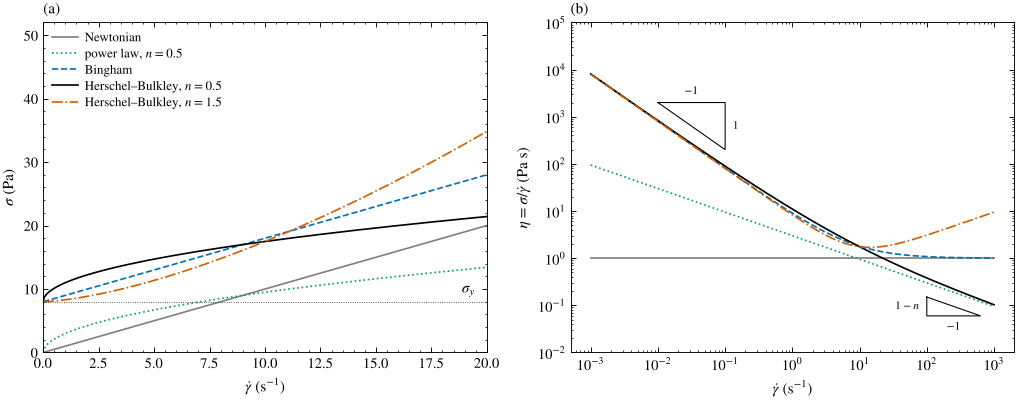

In [5]:
gdot = np.linspace(0, 20, 400)
gd_log = np.logspace(-3, 3, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
mine = {}
for lab, sy, K, n, col, ls in CASES:
    s_lin = hs.hb_stress(gdot, sy, K, n); eta = hs.hb_viscosity(gd_log, sy, K, n)
    ax1.plot(gdot, s_lin, ls, color=col, label=lab)
    ax2.loglog(gd_log, eta, ls, color=col, label=lab)
    mine[("(a)", lab)] = (gdot, s_lin); mine[("(b)", lab)] = (gd_log, eta)
ax1.axhline(8.0, color="k", lw=0.5, ls=(0, (1, 2)))
ax1.text(19.5, 8.6, r"$\sigma_y$", ha="right", va="bottom")
ax1.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", xlim=(0, 20), ylim=(0, 52))
ax1.legend(loc="upper left", fontsize=8.5); ax1.set_title("(a)", loc="left")
hs.slope_triangle(ax2, 1e-2, 2.0e3, 1.0, -1.0, "$1$", side="above", run_label="$-1$")
hs.slope_triangle(ax2, 1e2, 0.15, 0.8, -0.5, "$1-n$", side="below", run_label="$-1$")
ax2.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\eta=\sigma/\dot\gamma$ (Pa s)", ylim=(1e-2, 1e5))
ax2.set_title("(b)", loc="left")
fig.tight_layout(); plt.show()

In [6]:
ref = pd.read_csv(FIGDATA / "fig04_flow_curves.csv", comment="#")
worst = 0.0
for (panel, lab), (x, y) in mine.items():
    r = ref[(ref.panel == panel) & (ref.series == lab)].sort_values("index")
    assert len(r) == len(x)
    assert np.allclose(r.x.values, x, rtol=1e-8, atol=1e-12) and np.allclose(r.y.values, y, rtol=1e-8, atol=1e-12)
    worst = max(worst, np.max(np.abs(r.y.values - y) / np.maximum(np.abs(y), 1e-12)))
assert float(ref[ref.kind == "hline"].y.iloc[0]) == 8.0
print(f"Fig. 4: {len(mine)} curves x 400 points agree with fig04_flow_curves.csv "
      f"(largest relative difference {worst:.1e}, tolerance 1e-8)")

Fig. 4: 10 curves x 400 points agree with fig04_flow_curves.csv (largest relative difference 4.9e-10, tolerance 1e-8)


## 4. From one dimension to three: the tensorial law and the yield criterion

A rheometer measures one shear stress and one shear rate. To predict a pipe, a mixer or a settling particle we need the law for an arbitrary velocity field $\mathbf u$. Hohenemser and Prager (1932) did this for the Bingham material and Oldroyd (1947) gave it its rational form; replacing the linear viscous term by a power law gives

$$\boldsymbol\tau = \left(\frac{\sigma_y}{\dot\gamma} + K\dot\gamma^{\,n-1}\right)2\mathbf D \quad\text{if } \sigma>\sigma_y\ \text{(yielded)},\qquad \mathbf D = \mathbf 0\quad\text{if } \sigma\le\sigma_y\ \text{(unyielded)}, \tag{4}$$

with

- $\mathbf D = \tfrac12(\nabla\mathbf u + \nabla\mathbf u^{T})$, the rate-of-deformation tensor, and $\dot\gamma = \sqrt{2\,\mathbf D:\mathbf D}$ its magnitude;
- $\sigma = \sqrt{\tfrac12\,\boldsymbol\tau:\boldsymbol\tau}$, the stress magnitude, which reduces to $|\sigma_{21}|$ in simple shear.

The criterion $\sigma = \sigma_y$ is the **von Mises** (or $J_2$) criterion: since $\boldsymbol\tau$ is traceless for the HB law, $\sigma = \sqrt{J_2}$ with $J_2 = \tfrac12\boldsymbol\tau_d:\boldsymbol\tau_d$. Two separate assumptions are built in: the yield function (von Mises) and an *associated* flow rule ($\mathbf D$ parallel to $\boldsymbol\tau$). Both are assumptions about isotropic soft solids, not consequences of the measured flow curve. In an unyielded region the stress is not determined by Eq. (4); a plug may still translate or rotate rigidly, so the diagnostic of a plug is $\mathbf D = 0$, not $\mathbf u = 0$.

Below, `hb_tau` evaluates Eq. (4) for a given velocity gradient (yielded branch). We apply it to three flows.

In [7]:
def hb_tau(grad_u, sy, K, n):
    """Extra stress of the yielded HB law, Eq. (4), for a velocity-gradient matrix grad_u (1/s)."""
    D = 0.5 * (grad_u + grad_u.T)
    gdot = np.sqrt(2 * np.tensordot(D, D))           # gdot = sqrt(2 D:D)
    return (sy / gdot + K * gdot**(n - 1)) * 2 * D, gdot

def magnitude(tau):
    return np.sqrt(0.5 * np.tensordot(tau, tau))       # sigma = sqrt(tau:tau / 2)

sy, K, n = 8.0, 3.0, 0.5
# (i) simple shear u = (gdot*y, 0, 0)
gd = 4.0
L = np.zeros((3, 3)); L[0, 1] = gd                     # L[i, j] = du_i/dx_j (D is symmetric either way)
tau, gdot = hb_tau(L, sy, K, n)
print(f"simple shear: gdot = {gdot:.3f}, tau_12 = {tau[0,1]:.4f} Pa, HB: {hs.hb_stress(gd, sy, K, n):.4f} Pa")
print(f"   N1 = tau_11 - tau_22 = {tau[0,0]-tau[1,1]:.1f}, N2 = tau_22 - tau_33 = {tau[1,1]-tau[2,2]:.1f}; "
      f"stress magnitude = {magnitude(tau):.4f} Pa")
assert np.isclose(tau[0, 1], hs.hb_stress(gd, sy, K, n)) and np.isclose(magnitude(tau), tau[0, 1])

simple shear: gdot = 4.000, tau_12 = 14.0000 Pa, HB: 14.0000 Pa
   N1 = tau_11 - tau_22 = 0.0, N2 = tau_22 - tau_33 = 0.0; stress magnitude = 14.0000 Pa


In simple shear the tensorial law gives back Eq. (3) and **zero normal-stress differences**; real yield-stress fluids show $N_1>0$, $N_2<0$ (de Cagny et al. 2019; Sec. IX C), which lies outside the baseline model.

**Extensional flows** (Sec. IV E). In uniaxial extension at rate $\dot\epsilon$, $\mathbf D = \mathrm{diag}(-\dot\epsilon/2, -\dot\epsilon/2, \dot\epsilon)$ and $\dot\gamma = \sqrt3\,\dot\epsilon$; in planar extension $\mathbf D = \mathrm{diag}(\dot\epsilon, -\dot\epsilon, 0)$ and $\dot\gamma = 2\dot\epsilon$. Eq. (4) then predicts the net tensile stresses

$$\sigma_E = \tau_{zz}-\tau_{xx} = \sqrt3\,\sigma_y + 3^{(n+1)/2}K\dot\epsilon^{\,n}, \tag{11}$$
$$\sigma_P = \tau_{11}-\tau_{22} = 2\sigma_y + 2^{n+1}K\dot\epsilon^{\,n}. \tag{12}$$

Let us confirm both with `hb_tau`, and the Newtonian Trouton ratios 3 and 4.

In [8]:
for eps in [0.01, 1.0, 50.0]:
    tauU, _ = hb_tau(np.diag([-eps / 2, -eps / 2, eps]), sy, K, n)
    tauP, _ = hb_tau(np.diag([eps, -eps, 0.0]), sy, K, n)
    eq11 = np.sqrt(3) * sy + 3**((n + 1) / 2) * K * eps**n
    eq12 = 2 * sy + 2**(n + 1) * K * eps**n
    assert np.isclose(tauU[2, 2] - tauU[0, 0], eq11) and np.isclose(tauP[0, 0] - tauP[1, 1], eq12)
    print(f"eps = {eps:5.2f} 1/s: sigma_E = {tauU[2,2]-tauU[0,0]:8.3f} Pa (Eq. 11: {eq11:8.3f}); "
          f"sigma_P = {tauP[0,0]-tauP[1,1]:8.3f} Pa (Eq. 12: {eq12:8.3f})")
# Newtonian limit: Trouton ratios
mu, eps = 2.0, 0.7
tU, _ = hb_tau(np.diag([-eps / 2, -eps / 2, eps]), 0.0, mu, 1.0)
tP, _ = hb_tau(np.diag([eps, -eps, 0.0]), 0.0, mu, 1.0)
print(f"Newtonian: uniaxial viscosity / mu = {(tU[2,2]-tU[0,0])/eps/mu:.3f}, planar / mu = {(tP[0,0]-tP[1,1])/eps/mu:.3f}")

eps =  0.01 1/s: sigma_E =   14.540 Pa (Eq. 11:   14.540); sigma_P =   16.849 Pa (Eq. 12:   16.849)
eps =  1.00 1/s: sigma_E =   20.695 Pa (Eq. 11:   20.695); sigma_P =   24.485 Pa (Eq. 12:   24.485)
eps = 50.00 1/s: sigma_E =   62.212 Pa (Eq. 11:   62.212); sigma_P =   76.000 Pa (Eq. 12:   76.000)
Newtonian: uniaxial viscosity / mu = 3.000, planar / mu = 4.000


**Von Mises versus Tresca** (Sec. IV B). A general isotropic yield function depends on $J_2$ and on the Lode angle $\theta$, defined by $\cos3\theta = \tfrac{3\sqrt3}{2}J_3/J_2^{3/2}$ with $J_3 = \det\boldsymbol\tau_d$. Von Mises ignores $\theta$; the Tresca criterion, $\max_i\tau_i - \min_i\tau_i = 2\sigma_y$ in terms of the principal stresses, does not. Calibrated in simple shear, Tresca is the hexagon that touches the von Mises circle in pure shear ($J_3=0$, $\theta = 30°$) and is stronger elsewhere by up to $2/\sqrt3\approx1.155$, reached in uniaxial extension, where the two criteria predict tensile yield stresses $\sqrt3\,\sigma_y$ and $2\sigma_y$.

The cell below builds deviatoric principal stresses for every Lode angle, scales them to the Tresca yield surface, and compares their $\sqrt{J_2}$ with the von Mises value $\sigma_y$. (The parameterization by $\theta$ is standard plasticity, added here for illustration.)

Tresca / von Mises strength: 1.0000 (pure shear, theta = 30 deg) to 1.1547 (uniaxial, theta = 0); 2/sqrt(3) = 1.1547


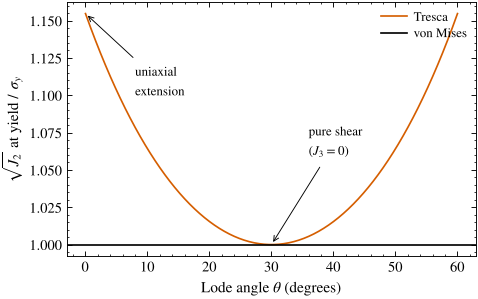

In [9]:
theta = np.linspace(0, np.pi / 3, 301)
k = np.arange(3)[:, None]
s_unit = (2 / np.sqrt(3)) * np.cos(theta - 2 * np.pi * k / 3)      # principal deviatoric stresses with sqrt(J2) = 1
J2 = 0.5 * np.sum(s_unit**2, axis=0); J3 = np.prod(s_unit, axis=0)
assert np.allclose(J2, 1) and np.allclose(1.5 * np.sqrt(3) * J3 / J2**1.5, np.cos(3 * theta))
ratio = 2 / (s_unit.max(0) - s_unit.min(0))     # sqrt(J2) on the Tresca surface / sigma_y  (von Mises: 1)
print(f"Tresca / von Mises strength: {ratio.min():.4f} (pure shear, theta = 30 deg) to "
      f"{ratio.max():.4f} (uniaxial, theta = 0); 2/sqrt(3) = {2/np.sqrt(3):.4f}")

fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.plot(np.degrees(theta), ratio, color=C["red"], label="Tresca")
ax.axhline(1, color=C["black"], label="von Mises")
ax.set(xlabel=r"Lode angle $\theta$ (degrees)", ylabel=r"$\sqrt{J_2}$ at yield $/\ \sigma_y$")
ax.annotate("uniaxial\nextension", (0, ratio[0]), (8, 1.1), fontsize=8.5, arrowprops=dict(arrowstyle="->", lw=0.6))
ax.annotate("pure shear\n($J_3=0$)", (30, 1.0), (36, 1.06), fontsize=8.5, arrowprops=dict(arrowstyle="->", lw=0.6))
ax.legend(loc="upper right", fontsize=8.5); plt.show()

Because the two criteria differ by at most 15%, and only when $J_3\neq0$, superposed shears and planar extension (both $J_3=0$) cannot separate them; uniaxial extension can. The review quotes the gravity-filament data of Geffrault et al. (2021); we redo the arithmetic:

In [10]:
for material, sy_shear, measured in [("kaolin suspension", 309, [517]), ("concentrated emulsion", 52, [98, 84])]:
    vm, tr = np.sqrt(3) * sy_shear, 2 * sy_shear
    dev = ", ".join(f"{m} Pa ({100*(m/vm-1):+.0f}% vs von Mises, {100*(m/tr-1):+.0f}% vs Tresca)" for m in measured)
    print(f"{material}: shear sigma_y = {sy_shear} Pa -> von Mises {vm:.0f} Pa, Tresca {tr:.0f} Pa; measured {dev}")

kaolin suspension: shear sigma_y = 309 Pa -> von Mises 535 Pa, Tresca 618 Pa; measured 517 Pa (-3% vs von Mises, -16% vs Tresca)
concentrated emulsion: shear sigma_y = 52 Pa -> von Mises 90 Pa, Tresca 104 Pa; measured 98 Pa (+9% vs von Mises, -6% vs Tresca), 84 Pa (-7% vs von Mises, -19% vs Tresca)


For the kaolin the measurement disfavors Tresca ($-16\%$ against a stated uncertainty of about 12%); for the emulsion the two nozzle sizes bracket von Mises (the review attributes the difference to capillarity).

## 5. Dimensionless groups (Table IV)

For a velocity scale $U$ and a length scale $L$, the principal groups are

$$\mathrm{Bn} = \frac{\sigma_y}{K(U/L)^n},\qquad \mathrm{Od} = \frac{\sigma_y L}{\eta_{\rm ref}U},\qquad \mathrm{Re}_K = \frac{\rho U^{2-n}L^n}{K}, \tag{8}$$

and for pipe flow with mean speed $U$ and diameter $D$ (not to be confused with the tensor $\mathbf D$) the Metzner–Reed Reynolds number

$$\mathrm{Re}_{MR} = \frac{\rho U^{2-n'}D^{n'}}{K'\,8^{\,n'-1}},\qquad n' = \frac{\mathrm d\ln\sigma_w}{\mathrm d\ln(8U/D)},\quad K' = \frac{\sigma_w}{(8U/D)^{n'}}. \tag{9}$$

For any laminar flow curve, and therefore for HB, Eq. (9) reduces to $\mathrm{Re}_{MR} = 8\rho U^2/\sigma_w$, so that the laminar Fanning friction factor $f_F \equiv 2\sigma_w/(\rho U^2) = 16/\mathrm{Re}_{MR}$. Table IV of the review adds:

| name | definition | context |
|---|---|---|
| Bingham (HB) number | $\mathrm{Bn} = \sigma_y/[K(U/L)^n]$ | yield versus viscous stress |
| Plasticity number | $\mathrm{Pl} = \mathrm{Bn}/(1+\mathrm{Bn})$ | bounded (0 to 1) measure of yield dominance |
| Hedström number | $\mathrm{He} = \rho D^2\sigma_y^{(2-n)/n}/K^{2/n}$ | pipe flow ($n=1$: $\rho D^2\sigma_y/\mu_p^2$) |
| Metzner–Reed Reynolds number | Eq. (9) | pipe flow and transition; $8\rho U^2/\sigma_w$ for HB |
| (gravity) yield number | $Y_g = 3\sigma_y/(2\Delta\rho\,gR)$ | sphere settling; arrest for $Y_g>0.143$ |
| Oldroyd number | $\mathrm{Od} = \sigma_yL/(\eta_{\rm ref}U)$ | creeping particle and bubble flows |

Critical values of any group can be compared only when the length scale and the prefactor are stated: Bn based on the radius differs from Bn based on the diameter by $2^n$, and Bn based on $8U/D$ by $8^n$.

In [11]:
def bingham_number(sy, K, n, U, L):      return sy / (K * (U / L)**n)
def plasticity_number(Bn):               return Bn / (1 + Bn)
def reynolds_K(rho, K, n, U, L):         return rho * U**(2 - n) * L**n / K
def hedstrom_number(rho, D, sy, K, n):   return rho * D**2 * sy**((2 - n) / n) / K**(2 / n)
def metzner_reed(rho, U, D, Kp, nprime): return rho * U**(2 - nprime) * D**nprime / (Kp * 8**(nprime - 1))
def yield_number(sy, drho, R, g=9.81):   return 3 * sy / (2 * drho * g * R)

# Bingham limit of the Hedstrom number
assert np.isclose(hedstrom_number(1000, 0.1, 5.0, 0.2, 1.0), 1000 * 0.1**2 * 5.0 / 0.2**2)
# An identity we derive here (not in the article): with L = D, He = Bn^((2-n)/n) * Re_K
for n_ in [0.3, 0.7, 1.0, 1.4]:
    args = dict(sy=5.0, K=0.5, n=n_)
    Bn_ = bingham_number(U=1.3, L=0.1, **args); ReK_ = reynolds_K(1200, 0.5, n_, 1.3, 0.1)
    assert np.isclose(hedstrom_number(1200, 0.1, **args), Bn_**((2 - n_) / n_) * ReK_)
print("He = Bn^((2-n)/n) Re_K verified: the velocity cancels from this combination of Bn and Re_K")

He = Bn^((2-n)/n) Re_K verified: the velocity cancels from this combination of Bn and Re_K


## 6. A worked example: a slurry pipeline (Supplementary Note S15 B, Example 1)

> A slurry with $\sigma_y = 5$ Pa, $K = 0.5$ Pa s$^{0.7}$, $n = 0.7$, $\rho = 1200$ kg m$^{-3}$ is pumped at $Q = 10$ L/s through $L = 500$ m of 100 mm pipe.

**Step 1 — the wall stress.** Momentum balance gives $\sigma_w = GR/2$ for a pressure gradient $G$, and the material is unyielded inside the plug radius $r_p = R\sigma_y/\sigma_w = R\phi$. Integrating Eq. (3) across the yielded annulus gives the flow rate

$$Q = \pi R^3 n\left(\frac{\sigma_w}{K}\right)^{1/n}(1-\phi)^{\frac{n+1}{n}}\left[\frac{(1-\phi)^2}{3n+1} + \frac{2\phi(1-\phi)}{2n+1} + \frac{\phi^2}{n+1}\right], \tag{19}$$

which is implicit in $\sigma_w$ for a prescribed $Q$. We code Eq. (19) directly, check it against `pipe_flux` of `scripts/hb_prediction.py` and against its limits, and solve for $\sigma_w$ by bracketing root finding.

In [12]:
def Q_eq19(sw, R, sy, K, n):
    """Laminar no-slip HB pipe flow rate, Eq. (19), SI units; zero below the yield stress."""
    if sw <= sy:
        return 0.0
    phi = sy / sw
    return (np.pi * R**3 * n * (sw / K)**(1 / n) * (1 - phi)**((n + 1) / n)
            * ((1 - phi)**2 / (3 * n + 1) + 2 * phi * (1 - phi) / (2 * n + 1) + phi**2 / (n + 1)))

R = 0.05
for sw in [6.0, 20.0, 300.0]:
    assert np.isclose(Q_eq19(sw, R, 5.0, 0.5, 0.7), pipe_flux(sw, R, 5.0, 0.5, 0.7), rtol=1e-12)
# limits: Newtonian (Hagen-Poiseuille), power law (phi = 0), Bingham (Buckingham-Reiner)
mu, sw = 0.2, 10.0
assert np.isclose(Q_eq19(sw, R, 0.0, mu, 1.0), np.pi * R**4 * (2 * sw / R) / (8 * mu))
assert np.isclose(Q_eq19(sw, R, 0.0, 0.5, 0.7), np.pi * R**3 * 0.7 / (3 * 0.7 + 1) * (sw / 0.5)**(1 / 0.7))
phi = 0.3
assert np.isclose(Q_eq19(sw, R, phi * sw, mu, 1.0), np.pi * R**3 * sw / (4 * mu) * (1 - 4 * phi / 3 + phi**4 / 3))
print("Eq. (19) agrees with hb_prediction.pipe_flux and with its Newtonian, power-law and Buckingham-Reiner limits")

Eq. (19) agrees with hb_prediction.pipe_flux and with its Newtonian, power-law and Buckingham-Reiner limits


In [13]:
sy, K, n, rho = 5.0, 0.5, 0.7, 1200.0           # slurry (S15 B, Example 1)
Q, D, Lpipe = 10e-3, 0.100, 500.0                # m^3/s, m, m
R = D / 2
sw = brentq(lambda s: Q_eq19(s, R, sy, K, n) - Q, sy * (1 + 1e-12), 1e4, xtol=1e-12)
phi = sy / sw
dp = 4 * sw * Lpipe / D                          # = G L with G = 2 sigma_w / R
U = Q / (np.pi * R**2)
print(f"wall stress sigma_w = {sw:.1f} Pa, phi = {phi:.2f}, plug radius = {1e3 * phi * R:.1f} mm")
print(f"pressure drop over {Lpipe:.0f} m = {dp / 1e3:.0f} kPa; mean velocity U = {U:.2f} m/s; 8U/D = {8 * U / D:.1f} 1/s")
assert abs(sw - 20.0) < 0.05 and abs(dp / 1e3 - 401) < 0.5 and abs(U - 1.27) < 0.005

wall stress sigma_w = 20.0 Pa, phi = 0.25, plug radius = 12.5 mm
pressure drop over 500 m = 401 kPa; mean velocity U = 1.27 m/s; 8U/D = 101.9 1/s


**Step 2 — the Metzner–Reed Reynolds number and the friction factor.** We obtain $n'$ as the local slope of $\ln\sigma_w$ against $\ln(8U/D)$ by solving Eq. (19) at slightly smaller and larger flow rates, then $K'$, and evaluate Eq. (9). It must agree with the shortcut $8\rho U^2/\sigma_w$, and $16/\mathrm{Re}_{MR}$ must reproduce the friction factor $2\sigma_w/(\rho U^2)$.

In [14]:
def wall_stress(Qv):
    return brentq(lambda s: Q_eq19(s, R, sy, K, n) - Qv, sy * (1 + 1e-12), 1e4, xtol=1e-13)

h = 1e-4
nprime = (np.log(wall_stress(Q * (1 + h))) - np.log(wall_stress(Q * (1 - h)))) / (np.log(1 + h) - np.log(1 - h))
Kprime = sw / (8 * U / D)**nprime
Re_MR = metzner_reed(rho, U, D, Kprime, nprime)
fF = 2 * sw / (rho * U**2)
print(f"n' = {nprime:.2f} (compare n = {n}),  K' = {Kprime:.2f} Pa s^n'")
print(f"Re_MR from Eq. (9) = {Re_MR:.0f};  8 rho U^2 / sigma_w = {8 * rho * U**2 / sw:.0f}")
print(f"Fanning friction factor 2 sigma_w/(rho U^2) = {fF:.5f};  16/Re_MR = {16 / Re_MR:.5f}")
assert abs(nprime - 0.48) < 0.005 and abs(Kprime - 2.18) < 0.005 and abs(Re_MR - 776) < 1
assert np.isclose(Re_MR, 8 * rho * U**2 / sw) and np.isclose(fF, 16 / Re_MR)

n' = 0.48 (compare n = 0.7),  K' = 2.18 Pa s^n'
Re_MR from Eq. (9) = 776;  8 rho U^2 / sigma_w = 776
Fanning friction factor 2 sigma_w/(rho U^2) = 0.02061;  16/Re_MR = 0.02061


The local index $n' = 0.48$ differs markedly from $n = 0.7$ because the yield stress contributes to the slope of the wall flow curve, exactly as in the 1926 data of notebook 01. $\mathrm{Re}_{MR}\approx 776$: the flow is laminar (transition criteria for HB pipe flow are discussed in Supplementary Note S12).

**Step 3 — the remaining groups of Table IV.** With $L = D$ and the mean velocity $U$ as scales:

In [15]:
Bn = bingham_number(sy, K, n, U, D)
groups = pd.Series({
    "Bn = sigma_y/[K (U/D)^n]": Bn,
    "Pl = Bn/(1+Bn)": plasticity_number(Bn),
    "He = rho D^2 sigma_y^((2-n)/n) / K^(2/n)": hedstrom_number(rho, D, sy, K, n),
    "Re_K = rho U^(2-n) D^n / K": reynolds_K(rho, K, n, U, D),
    "Re_MR (Eq. 9)": Re_MR,
    "phi = sigma_y/sigma_w": phi,
    "Bn based on R instead of D": bingham_number(sy, K, n, U, R),
    "Bn based on 8U/D": sy / (K * (8 * U / D)**n),
})
groups.round(3).to_frame("value")

,value
Bn = sigma_y/[K (U/D)^n],1.685
Pl = Bn/(1+Bn),0.628
He = rho D^2 sigma_y^((2-n)/n) / K^(2/n),1727.246
Re_K = rho U^(2-n) D^n / K,655.533
Re_MR (Eq. 9),776.263
phi = sigma_y/sigma_w,0.249
Bn based on R instead of D,1.037
Bn based on 8U/D,0.393


The last two rows make the warning of Sec. IV C concrete: the same flow has Bn between about 0.4 and 1.7 depending on the convention. Always state it.

**Step 4 — the threshold for flow and the pressure–flow curve.** In a no-slip pipe nothing moves unless $|\mathrm dp/\mathrm dz| > 2\sigma_y/R$, Eq. (22). For this line, restarting the flow therefore needs at least $2\sigma_y L/R$ = 100 kPa over 500 m, whatever $K$ and $n$ are (for a gelled material the breakaway stress can be higher than the steady-flow intercept). The plot shows the pressure drop over the full range of flow rates, using `pressure_gradient` from `hb_prediction.py`, and the local index $n'$ along the curve.

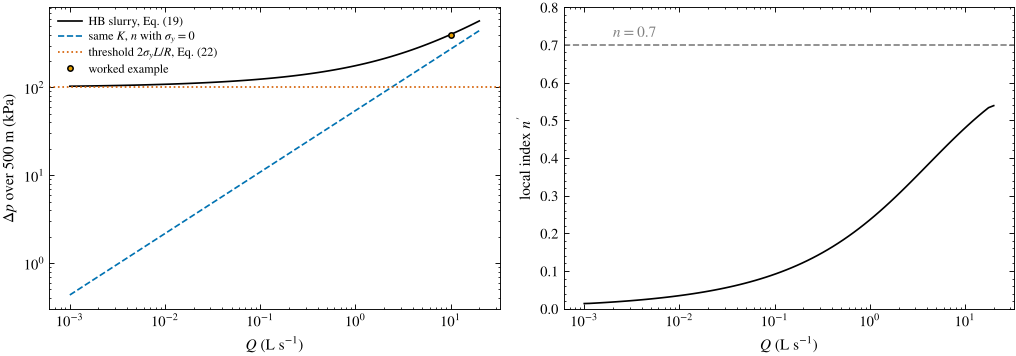

restart threshold: 100 kPa over 500 m
at the top of the range (20 L/s) Re_MR = 8 rho U^2/sigma_w = 2176; Eq. (19) is a laminar solution, so check Re_MR before using it at higher flow rates


In [16]:
Qs = np.logspace(-6, np.log10(0.02), 80)                         # m^3/s, up to 20 L/s
dps = np.array([pressure_gradient(q, R, sy, K, n) for q in Qs]) * Lpipe
dp_min = 2 * sy / R * Lpipe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.5))
ax1.loglog(Qs * 1e3, dps / 1e3, color=C["black"], label="HB slurry, Eq. (19)")
ax1.loglog(Qs * 1e3, np.array([pressure_gradient(q, R, 0.0, K, n) for q in Qs]) * Lpipe / 1e3,
           "--", color=C["blue"], label=r"same $K$, $n$ with $\sigma_y=0$")
ax1.axhline(dp_min / 1e3, color=C["red"], ls=":", label=r"threshold $2\sigma_yL/R$, Eq. (22)")
ax1.plot(Q * 1e3, dp / 1e3, "o", color=C["orange"], mec="k", label="worked example")
ax1.set(xlabel=r"$Q$ (L s$^{-1}$)", ylabel=r"$\Delta p$ over 500 m (kPa)"); ax1.legend(fontsize=8)
sws = dps * R / (2 * Lpipe); rates = 8 * (Qs / (np.pi * R**2)) / D
ax2.semilogx(Qs * 1e3, np.gradient(np.log(sws), np.log(rates)), color=C["black"])
ax2.axhline(n, color=C["grey"], ls="--"); ax2.text(2e-3, n + 0.02, f"$n = {n}$", color=C["grey"])
ax2.set(xlabel=r"$Q$ (L s$^{-1}$)", ylabel=r"local index $n'$", ylim=(0, 0.8))
fig.tight_layout(); plt.show()
print(f"restart threshold: {dp_min / 1e3:.0f} kPa over {Lpipe:.0f} m")
U_top = Qs[-1] / (np.pi * R**2)
print(f"at the top of the range (20 L/s) Re_MR = 8 rho U^2/sigma_w = {8 * rho * U_top**2 / sws[-1]:.0f}; "
      "Eq. (19) is a laminar solution, so check Re_MR before using it at higher flow rates")

At low flow rates the pressure drop approaches the yield threshold and $n'\to0$; at higher rates the yield stress matters less and $n'$ rises toward $n$.

**Step 5 — will a cutting settle?** (Supplementary Note S15 B, Example 3.) A sphere of radius $R_p$ is held at rest in an ideal, unbounded, no-slip Bingham material when the yield number $Y_g = 3\sigma_y/(2\Delta\rho\,gR_p)$ exceeds about 0.143 (Beris et al. 1985); Tabuteau et al. (2007) measured 0.145 in Carbopol. Equivalently, the radius-based number without the factor 3/2, $Y_R = \sigma_y/(\Delta\rho\,gR_p)$, has the threshold $2\times0.143/3 = 0.0953$ (Sec. VIII E; Note S15 B). For a 5 mm particle with $\Delta\rho = 1500$ kg m$^{-3}$:

In [17]:
Yg_c, drho, Rp = 0.143, 1500.0, 2.5e-3
sy_needed = Yg_c * 2 * drho * 9.81 * Rp / 3
print(f"yield stress needed to hold the cutting: {sy_needed:.2f} Pa; equivalently Y_R = sigma_y/(drho g R_p) > {2 * Yg_c / 3:.4f}")
print(f"our slurry (sigma_y = {sy} Pa): Yg = {yield_number(sy, drho, Rp):.3f} -> "
      f"{'held at rest' if yield_number(sy, drho, Rp) > Yg_c else 'settles'} in the ideal static problem")
assert abs(sy_needed - 3.51) < 0.01

yield stress needed to hold the cutting: 3.51 Pa; equivalently Y_R = sigma_y/(drho g R_p) > 0.0953
our slurry (sigma_y = 5.0 Pa): Yg = 0.204 -> held at rest in the ideal static problem


The static limit is independent of $K$ and $n$; the settling *speed* above onset is not. Shape, walls, elasticity, thixotropy and an imposed shear flow all limit how far this screening estimate transfers to real cuttings.

## Try it yourself

**Exercise 1 — the plug.** For the slurry of Sec. 6, find the flow rate at which the plug fills half the pipe radius ($\phi = 0.5$). *Hint:* set $\sigma_w = 2\sigma_y$ and evaluate `Q_eq19`.

<details><summary>Solution</summary>

```python
Q_half = Q_eq19(2 * sy, R, sy, K, n)
print(f"{Q_half * 1e3:.3f} L/s")
```
The plug fills half the radius at $Q \approx 1.61$ L/s, about one sixth of the design flow rate of 10 L/s (where $\phi = 0.25$).
</details>

**Exercise 2 — power-law check of Eq. (9).** For a power-law fluid ($\sigma_y = 0$) the review states $n' = n$ and $K' = K[(3n+1)/(4n)]^n$. Verify both numerically with `wall_stress` (after setting `sy = 0`; use a small positive value such as `1e-12` to keep the bracket valid), and show that $\mathrm{Re}_{MR}$ then equals $\rho U^{2-n}D^n/\{K\,8^{n-1}[(3n+1)/(4n)]^n\}$.

<details><summary>Solution</summary>

```python
sy_keep, sy = sy, 1e-12                     # wall_stress uses the global sy
for Qv in [2e-3, 10e-3]:
    U_ = Qv / (np.pi * R**2); sw_ = wall_stress(Qv); h = 1e-4
    npr = (np.log(wall_stress(Qv * (1 + h))) - np.log(wall_stress(Qv * (1 - h)))) / (np.log(1 + h) - np.log(1 - h))
    Kpr = sw_ / (8 * U_ / D)**npr
    Re_pl = rho * U_**(2 - n) * D**n / (K * 8**(n - 1) * ((3 * n + 1) / (4 * n))**n)
    print(f"Q = {Qv*1e3:.0f} L/s: n' = {npr:.6f}, K' = {Kpr:.6f}, K[(3n+1)/(4n)]^n = {K*((3*n+1)/(4*n))**n:.6f}, "
          f"Re_MR = {metzner_reed(rho, U_, D, Kpr, npr):.2f}, formula = {Re_pl:.2f}")
sy = sy_keep                                # restore the slurry
```
At both flow rates $n' = 0.700000$ and $K' = 0.536924$ Pa s$^{0.7}$, equal to $n$ and $K[(3n+1)/(4n)]^n$; the local index no longer depends on the operating point. $\mathrm{Re}_{MR}$ from Eq. (9) agrees with the closed form (140.58 at 2 L/s, 1139.14 at 10 L/s). Compare $n' = 0.48$ for the slurry with its 5 Pa yield stress.
</details>

**Exercise 3 — yield dominance.** Plot $\mathrm{Bn}$, $\mathrm{Pl}$ and $\phi = \sigma_y/\sigma_w$ against $Q$ for the slurry from $10^{-3}$ to $10^{2}$ L/s. Which of them tend to 1 as $Q\to0$, and which grows without bound? Why is $\phi$, unlike Bn, free of any choice of velocity and length scale?

<details><summary>Solution</summary>

```python
Qs3 = np.logspace(-3, 2, 200) * 1e-3                       # m^3/s
sws3 = np.array([wall_stress(q) for q in Qs3])             # laminar wall stress, Eq. (19)
U3 = Qs3 / (np.pi * R**2)
Bn3 = bingham_number(sy, K, n, U3, D)
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.loglog(Qs3 * 1e3, Bn3, label="Bn"); ax.loglog(Qs3 * 1e3, plasticity_number(Bn3), label="Pl")
ax.loglog(Qs3 * 1e3, sy / sws3, label=r"$\phi$"); ax.set(xlabel="Q (L/s)"); ax.legend(); plt.show()
```
As $Q\to0$ both Pl and $\phi$ tend to 1 (0.999 and 0.97 at $10^{-3}$ L/s), whereas Bn grows without bound (about 1060 there, against 0.34 at 100 L/s). $\phi$ is the ratio of two stresses fixed by the momentum balance, $\sigma_y$ and $\sigma_w = GR/2$, so it needs no velocity or length scale; it is also the plug radius $r_p/R$. Bn and Pl change with the choice of $U$ and $L$ (Sec. IV C). Note that above about 20 L/s $\mathrm{Re}_{MR}$ exceeds 2100 (about $2\times10^4$ at 100 L/s), so the laminar Eq. (19) used here no longer applies (notebook 08).
</details>

**Exercise 4 — normal stresses.** Use `hb_tau` to show that for *any* steady simple shear rate the HB law gives $N_1 = N_2 = 0$, and that in uniaxial extension the stress magnitude $\sqrt{\tfrac12\boldsymbol\tau:\boldsymbol\tau}$ equals $\sigma_y + K\dot\gamma^{\,n}$ with $\dot\gamma = \sqrt3\dot\epsilon$. What does that say about the role of the scalar flow curve in the tensorial law?

<details><summary>Hint for Exercise 4</summary>

`tau, gdot = hb_tau(np.diag([-e/2, -e/2, e]), sy, K, n); magnitude(tau), hs.hb_stress(gdot, sy, K, n)`
</details>

<details><summary>Solution</summary>

```python
for gd_ in [0.01, 1.0, 300.0]:                                   # simple shear at several rates
    Lg = np.zeros((3, 3)); Lg[0, 1] = gd_
    t_, _ = hb_tau(Lg, sy, K, n)
    print(f"shear {gd_}: N1 = {t_[0,0]-t_[1,1]}, N2 = {t_[1,1]-t_[2,2]}")
for e in [0.01, 1.0, 50.0]:                                      # uniaxial extension
    t_, g_ = hb_tau(np.diag([-e / 2, -e / 2, e]), sy, K, n)
    print(f"extension {e}: gdot = {g_:.4f} = sqrt(3)*eps = {np.sqrt(3)*e:.4f}; "
          f"|tau| = {magnitude(t_):.4f}, sigma_y + K gdot^n = {hs.hb_stress(g_, sy, K, n):.4f}")
```
In simple shear $N_1 = N_2 = 0$ exactly at every rate, because $\mathbf D$ has no diagonal components. In uniaxial extension $\dot\gamma = \sqrt3\,\dot\epsilon$ and the stress magnitude equals $\sigma_y + K\dot\gamma^n$ to machine precision (for example 5.73 Pa at $\dot\epsilon = 1$ s$^{-1}$ and 16.36 Pa at 50 s$^{-1}$ with the slurry parameters). The tensorial law applies the scalar flow curve to the invariants: the magnitude of the stress is always $\sigma_y + K\dot\gamma^n$ evaluated at $\dot\gamma = \sqrt{2\mathbf D:\mathbf D}$, whatever the flow, and only the direction of $\boldsymbol\tau$ (parallel to $\mathbf D$, the associated flow rule) changes. A shear calibration therefore fixes every term of Eqs. (11) and (12).
</details>

## Key points
- $\sigma = \sigma_y + K\dot\gamma^n$ contains the Newtonian ($\sigma_y=0$, $n=1$), power-law ($\sigma_y=0$) and Bingham ($n=1$) models; $\dot\gamma_y = (\sigma_y/K)^{1/n}$ or a reference-rate amplitude $A$ give parameters with consistent units.
- The apparent viscosity diverges as $\sigma_y/\dot\gamma$ at low rates (slope $-1$, shared by all ideal yield-stress models) and follows $K\dot\gamma^{n-1}$ at high rates; for $n>1$ it has a minimum.
- The tensorial law, Eq. (4), combines the scalar flow curve with two separate assumptions, the von Mises yield function and an associated flow rule; it predicts no normal-stress differences in shear, and tensile stresses $\sqrt3\sigma_y + 3^{(n+1)/2}K\dot\epsilon^n$ (uniaxial) and $2\sigma_y + 2^{n+1}K\dot\epsilon^n$ (planar).
- Von Mises and Tresca agree in pure shear and differ by up to 15% (uniaxial extension), so only tests with $J_3\neq0$ can distinguish them.
- Bn, Pl, He, $\mathrm{Re}_{MR}$ and $Y_g$ summarize yield dominance, inertia and arrest; for laminar HB pipe flow $\mathrm{Re}_{MR} = 8\rho U^2/\sigma_w$ and $f_F = 16/\mathrm{Re}_{MR}$. Critical values are meaningful only with their length and velocity conventions stated.

## References

The review and its repository:
- Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

- W. H. Herschel and R. Bulkley (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
- E. C. Bingham (1916). An investigation of the laws of plastic flow. *Bulletin of the Bureau of Standards* **13**, 309–353. https://doi.org/10.6028/bulletin.304
- A. de Waele (1923). Viscometry and plastometry. *Journal of the Oil and Colour Chemists' Association* **6**, 33–88.
- W. Ostwald (1925). Ueber die Geschwindigkeitsfunktion der Viskosität disperser Systeme. I. *Kolloid-Zeitschrift* **36**, 99–117. https://doi.org/10.1007/bf01431449
- E. Buckingham (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
- K. Hohenemser and W. Prager (1932). Über die Ansätze der Mechanik isotroper Kontinua. *ZAMM – Zeitschrift für Angewandte Mathematik und Mechanik* **12**, 216–226. https://doi.org/10.1002/zamm.19320120403
- J. G. Oldroyd (1947). A rational formulation of the equations of plastic flow for a Bingham solid. *Mathematical Proceedings of the Cambridge Philosophical Society* **43**, 100–105. https://doi.org/10.1017/s0305004100023239
- A. B. Metzner and J. C. Reed (1955). Flow of non-Newtonian fluids—correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409
- A. Z. Nelson and R. H. Ewoldt (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**, 7578–7594. https://doi.org/10.1039/C7SM00758B
- A. Saasen and J. D. Ytrehus (2020). Viscosity models for drilling fluids—Herschel–Bulkley parameters and their use. *Energies* **13**, 5271. https://doi.org/10.3390/en13205271
- H. de Cagny, M. Fazilati, M. Habibi, M. M. Denn and D. Bonn (2019). The yield normal stress. *Journal of Rheology* **63**, 285–290. https://doi.org/10.1122/1.5063796
- A. Geffrault, H. Bessaies-Bey, N. Roussel and P. Coussot (2021). Extensional gravity-rheometry (EGR) for yield stress fluids. *Journal of Rheology* **65**, 887–901. https://doi.org/10.1122/8.0000241
- A. N. Beris, J. A. Tsamopoulos, R. C. Armstrong and R. A. Brown (1985). Creeping motion of a sphere through a Bingham plastic. *Journal of Fluid Mechanics* **158**, 219–244. https://doi.org/10.1017/s0022112085002622
- H. Tabuteau, P. Coussot and J. R. de Bruyn (2007). Drag force on a sphere in steady motion through a yield-stress fluid. *Journal of Rheology* **51**, 125–137. https://doi.org/10.1122/1.2401614
- J. M. Dealy (1995). Official nomenclature for material functions describing the response of a viscoelastic fluid to various shearing and extensional deformations. *Journal of Rheology* **39**, 253–265. https://doi.org/10.1122/1.4765670

### Further reading

- R. B. Bird, G. C. Dai and B. J. Yarusso (1983). The Rheology and Flow of Viscoplastic Materials. *Reviews in Chemical Engineering* **1**, 1–70. https://doi.org/10.1515/revce-1983-0102
- R. P. Chhabra and J. F. Richardson (2008). Non-Newtonian Flow and Applied Rheology: Engineering Applications. 2nd ed., Butterworth-Heinemann, Oxford.